# Predicting Loan Default on Lending Club

**Hands-on Machine Learning — Master 1 Computer Science, Artificial Intelligence — Final project**


**Data:** [All Lending Club loan data (Kaggle, wordsforthewise)](https://www.kaggle.com/datasets/wordsforthewise/lending-club) — we use `accepted_2007_to_2018Q4.csv`.
The data is not included. To run this notebook, download it and place the CSV at
`dataset_accepted_2007_to_2018Q4/accepted_2007_to_2018Q4.csv` next to this notebook.

## 1. Introduction

### 1.1 The task

Lending Club was a US peer-to-peer lending platform: borrowers applied for personal loans (up to \$40k, over 36 or 60 months) and investors funded them.
When a loan is approved we know everything about the **application** (income, debt-to-income ratio, credit history, FICO score, loan amount, purpose...),
but whether the borrower will actually repay is only known **years later**.

**Goal:** using only information available *at the time the loan is issued*, predict whether a loan will end as
**Fully Paid (0)** or **Charged Off (1)**.

- **Type:** binary classification, imbalanced (~15–20 % defaults).
- **Not a time series:** each row is an independent loan, but every loan has an issue date, and the borrower population and default rate drift over the years. We therefore evaluate with a **chronological split** (train on older loans, test on newer ones), which is how such a model would be used in practice.
- **Who would use it:** an investor deciding which loans to fund. Missing a default (false negative) costs the lost principal; rejecting a good loan (false positive) only costs the forgone interest — so recall on defaults matters more than accuracy.

### 1.2 State of the art

Lending Club is one of the most studied credit datasets. We summarise **peer-reviewed publications** only. Scores from different papers are only comparable if the columns used and the split protocol are the same, which is rarely the case here, so we also state how each result was obtained.

| Work | Data and protocol | Models | Main finding |
|---|---|---|---|
| Serrano-Cinca, Gutierrez-Nieto & Lopez-Palacios, *PLOS ONE* 10(10), e0139427 (2015) | 24,449 36-month Lending Club loans issued 2008-2011 (the dataset runs to 2014, but only loans funded until 2011 had time to mature); survival analysis, then a logistic regression to predict default | Logistic regression | Lending Club's own grade is the most predictive factor of default; accuracy improves when other information is added, especially the borrower's debt level |
| Teply & Polena, *North American Journal of Economics and Finance* 51 (2020) | 212,252 Lending Club loans, 2009-2013, 23 variables; 10 classification algorithms compared | Logistic regression, LDA, neural networks, k-NN, trees, etc. | Logistic regression, artificial neural networks and linear discriminant analysis are the three best algorithms: simple models are very competitive |
| Ko, Lin, Do & Huang, *Entropy* 24(6), 801 (2022) | 60,993 loans issued 2018 Q3 to 2019 Q2, only Fully Paid / Charged Off kept; 3 statistical and 5 AI models; confusion-matrix metrics, AUC, KS, Student's t-test | LR, Bayes, LDA, decision tree, random forest, LightGBM, ANN, CNN | LightGBM is best: accuracy 68.57 % (2.91 points above the *average* of the other models, about 1.3 above the best one), ROC-AUC 0.749. The "USD 24 million" in the paper is an illustrative revenue estimate. Recent loans kept only when already finished: possibly affected by the survivorship bias shown in section 6 |
| Li, Sharma & Cheng, *Intelligent Systems with Applications* 26, 200514 (2025) | Lending Club data, LightGBM with SHAP and LIME explanations | LightGBM | Accuracy 0.87 (abstract); hard to interpret without the default rate, since predicting "Fully Paid" for everyone already gives about 0.85 |
| Muslim, Dasril, Sam'an & Ifriza, *IJEECS* 28(2), 1002-1011 (2022) | Lending Club data; swarm-based feature selection keeps 6 of 18 features; SMOTE | LightGBM (+ACO / BCO) | Accuracy 94.4-95.6 %, but with no leakage audit that we could verify |

**What we learn from the literature**
1. **Lending Club's grade is the strongest predictor** (Serrano-Cinca), so any useful model must be compared with it. This is why our baseline is the grade itself.
2. **Gradient boosting tends to be the best family** (Ko, Li), but **simple linear models stay competitive** (Teply & Polena). We therefore compare logistic regression, random forest and three gradient-boosting implementations, and expect small differences.
3. **Reported scores are hard to compare.** Most papers report accuracy, on different periods, with different default rates, and rarely a chronological split. With about 15-20 % defaults, an accuracy of 85 % is obtained by predicting "Fully Paid" for everyone, so accuracy is not informative. Very high scores (94 % and above) should be read with caution, since using columns recorded after the loan is issued (payments, recoveries) is a well-known source of inflated results.
4. **Which loans are included matters too.** Serrano-Cinca et al. only analyse loans that had time to mature, as we do. Keeping recent loans only when they are already finished biases the sample towards early defaults and inflates the score (section 6 shows ROC-AUC rising from about 0.71 to 0.75 for the same models).
5. **No result is directly comparable to ours** (out-of-time ROC-AUC on matured loans without post-issue columns). We therefore benchmark against the reference the platform itself provides, **Lending Club's grade**, inside exactly the same protocol.

**Where our solution sits** (ROC-AUC of our final model, tuned LightGBM; update if you re-run):

| | Validation 2014 | Test 2015 |
|---|---|---|
| Lending Club sub-grade only (reference) | 0.660 | 0.679 |
| Our Model A (no grade, no interest rate) | 0.687 | 0.699 |
| Our Model B (with Lending Club pricing) | 0.693 | 0.709 |

### 1.3 Why we chose this solution (arguments)

Our goal is a solution whose number can be **trusted** and that **answers a useful question**, rather than a high headline score:

1. **Strict, documented leakage removal.** Every dropped column is listed with a reason (48 columns, section 2.2). This is the main reason why very high scores in the literature are not comparable with ours.
2. **Only matured loans.** We keep loans whose full term ended before the data cut-off (676k loans, 2007-2015). The plot in 2.4 shows that keeping every finished loan makes recent years look riskier than they are, because early defaulters finish first; section 6 measures how much this inflates the score.
3. **Chronological split** (train up to 2013, validation 2014, test 2015, evaluated once at the end), as the model would be used in practice. Most of the papers above do not use one.
4. **A question beyond a headline score: can we beat Lending Club's own grade?** We compare a grade-only baseline, Model A (borrower data only) and Model B (A plus Lending Club's pricing). Model A, which never sees the grade, already beats the sub-grade, and within each grade it ranks borrowers better than the sub-grade does (section 4.5).
5. **Several model families compared**, as the literature suggests: logistic regression, random forest and gradient boosting in three implementations (scikit-learn's HistGradientBoosting, XGBoost and LightGBM), all tuned with the same budget on a time-aware split (`PredefinedSplit`) so tuning never sees the future. LightGBM wins on validation by a small margin (0.693, vs 0.692 for XGBoost and 0.688 for HistGradientBoosting), consistent with the literature, and is our final model.
6. **Class imbalance handled by evidence, not by habit.** Class weights and SMOTE did not improve the ranking and only distorted the probabilities (section 3.10), so we keep unweighted models and choose a cost-based decision threshold.
7. **Evaluation that goes beyond accuracy:** ROC-AUC, PR-AUC, Brier score and calibration curves, a cost-based threshold, per-grade analysis and an error analysis of the defaults the model misses.
8. **We explain why higher scores exist.** The appendix (section 6) reproduces a 0.75 ROC-AUC by keeping loans whose term had not ended, and shows it drops to about 0.71 once they are removed.

**References**
- Serrano-Cinca, C., Gutierrez-Nieto, B., Lopez-Palacios, L. (2015). Determinants of default in P2P lending. *PLOS ONE* 10(10): e0139427. https://doi.org/10.1371/journal.pone.0139427
- Teply, P., Polena, M. (2020). Best classification algorithms in peer-to-peer lending. *North American Journal of Economics and Finance* 51. https://ideas.repec.org/a/eee/ecofin/v51y2020ics1062940818302262.html
- Ko, P.-C., Lin, P.-C., Do, H.-T., Huang, Y.-F. (2022). P2P lending default prediction based on AI and statistical models. *Entropy* 24(6): 801. https://doi.org/10.3390/e24060801
- Li, L.-H., Sharma, A. K., Cheng, S.-T. (2025). Explainable AI based LightGBM prediction model to predict default borrower in social lending platform. *Intelligent Systems with Applications* 26: 200514. https://doi.org/10.1016/j.iswa.2025.200514
- Muslim, M. A., Dasril, Y., Sam'an, M., Ifriza, Y. N. (2022). An improved light gradient boosting machine algorithm based on swarm algorithms for predicting loan default of peer-to-peer lending. *IJEECS* 28(2): 1002-1011. http://doi.org/10.11591/ijeecs.v28.i2.pp1002-1011
- Dataset: Lending Club loan data (Kaggle). https://www.kaggle.com/datasets/wordsforthewise/lending-club

## 2. Preprocessing

### 2.1 Setup

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

import seaborn as sns
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

# pip install imbalanced-learn lightgbm xgboost
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", message="X does not have valid feature names")

RANDOM_STATE = 42

DATA_DIR = Path("dataset_accepted_2007_to_2018Q4")
CSV_PATH = DATA_DIR / "accepted_2007_to_2018Q4.csv"
CACHE_PATH = DATA_DIR / "finished_loans.parquet"   # created on first run

DATA_END = pd.Timestamp("2018-12-01")   # last issue month in the file
MISSING_THRESHOLD = 0.90                # drop columns missing in more than 90 % of loans

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

### 2.2 Column inventory: what we drop and why

The dataset contains 151 columns, including post-issuance information that could cause data leakage. We remove these columns and retain only information available when the loan is issued. All removed columns and their reasons are documented below.

In [ ]:
all_columns = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print(f"{len(all_columns)} columns in the file")

DROP_REASONS = {
    "Leakage: payments / status after issue": [
        "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv", "total_rec_prncp",
        "total_rec_int", "total_rec_late_fee", "recoveries", "collection_recovery_fee",
        "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
        "last_fico_range_high", "last_fico_range_low", "pymnt_plan",
    ],
    "Leakage: hardship / debt-settlement programmes": [
        c for c in all_columns
        if c.startswith(("hardship", "settlement", "debt_settlement"))
    ] + ["deferral_term", "payment_plan_start_date", "orig_projected_additional_accrued_interest"],
    "Identifier / URL": ["id", "member_id", "url"],
    "Free text or very high cardinality": ["desc", "title", "emp_title", "zip_code"],
    "Redundant with loan_amnt": ["funded_amnt", "funded_amnt_inv"],
    "Constant": ["policy_code"],
}

drop_table = pd.DataFrame(
    [(col, reason) for reason, cols in DROP_REASONS.items() for col in cols],
    columns=["column", "reason"],
)
assert drop_table["column"].isin(all_columns).all(), "unknown column in DROP_REASONS"

load_columns = [c for c in all_columns if c not in set(drop_table["column"])]
print(f"Dropped up front: {len(drop_table)}  ->  loaded: {len(load_columns)}")
drop_table.groupby("reason").size().rename("n_columns").to_frame()

151 columns in the file
Dropped up front: 48  ->  loaded: 103


,n_columns
reason,
Constant,1
Free text or very high cardinality,4
Identifier / URL,3
Leakage: hardship / debt-settlement programmes,22
Leakage: payments / status after issue,16
Redundant with loan_amnt,2


### 2.3 Loading the finished loans

The 1.6 GB CSV is processed in chunks, retaining loans with final outcomes and caching the result as Parquet. Loans with unknown outcomes (Current, Late, or In Grace Period) are excluded. Fully Paid represents successful repayment, while Charged Off and equivalent historical statuses represent unsuccessful repayment.

In [ ]:
TARGET_MAP = {
    "Fully Paid": 0,
    "Does not meet the credit policy. Status:Fully Paid": 0,
    "Charged Off": 1,
    "Does not meet the credit policy. Status:Charged Off": 1,
    "Default": 1,
}


def load_finished_loans(csv_path, columns, chunksize=300_000):
    # Read the CSV chunk by chunk and keep only loans whose outcome is known.
    chunks = []
    for chunk in pd.read_csv(csv_path, usecols=columns, chunksize=chunksize, low_memory=False):
        chunk = chunk[chunk["loan_status"].isin(TARGET_MAP)]
        float_cols = chunk.select_dtypes("float64").columns
        chunk[float_cols] = chunk[float_cols].astype("float32")
        chunks.append(chunk)
    return pd.concat(chunks, ignore_index=True)


if CACHE_PATH.exists():
    loans = pd.read_parquet(CACHE_PATH)
else:
    loans = load_finished_loans(CSV_PATH, load_columns)
    loans.to_parquet(CACHE_PATH, index=False)

print(f"{loans.shape[0]:,} finished loans x {loans.shape[1]} columns, "
      f"{loans.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")

1,348,099 finished loans x 103 columns, 1.74 GB in memory


In [ ]:
loans["y"] = loans["loan_status"].map(TARGET_MAP).astype("int8")
loans["issue_d"] = pd.to_datetime(loans["issue_d"], format="%b-%Y")
loans["term_months"] = loans["term"].str.extract(r"(\d+)", expand=False).astype(int)

display(loans["loan_status"].value_counts().to_frame())
print(f"Default rate (all finished loans): {loans['y'].mean():.3f}")

,count
loan_status,
Fully Paid,1076751
Charged Off,268559
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


Default rate (all finished loans): 0.200


### 2.4 Maturity filtering

Including loans that have not completed their full term creates survivorship bias because recent loans may appear disproportionately risky. We retain only loans whose full term ended before the data cut-off: 36-month loans issued by 2015 and 60-month loans issued by 2013.

In [ ]:
issue_month = loans["issue_d"].dt.year * 12 + loans["issue_d"].dt.month
cutoff_month = DATA_END.year * 12 + DATA_END.month
matured = issue_month + loans["term_months"] <= cutoff_month

rates = (loans.assign(issue_year=loans["issue_d"].dt.year)
              .groupby(["issue_year", "term"])["y"].mean().unstack())
ax = rates.plot(marker="o", figsize=(8, 4))
ax.axvline(2015.5, color="grey", ls="--")
ax.set(title="Default rate of finished loans by issue year", xlabel="Issue year", ylabel="Default rate")
plt.show()

df = loans[matured].drop(columns=["loan_status"]).reset_index(drop=True)
del loans
print(f"Matured loans kept: {len(df):,}  (default rate {df['y'].mean():.3f})")
df.groupby(df["issue_d"].dt.year)["y"].agg(n_loans="size", default_rate="mean")

<Figure size 800x400 with 1 Axes>

Matured loans kept: 676,302  (default rate 0.149)


,n_loans,default_rate
issue_d,,
2007,603,0.262023
2008,2393,0.207271
2009,5281,0.136906
2010,12537,0.140145
2011,21721,0.151789
2012,53367,0.161973
2013,134804,0.155960
2014,162570,0.137264
2015,283026,0.148863


### 2.5 Cleaning

- Convert text columns to numbers: `emp_length` ("10+ years" → 10), `earliest_cr_line` → credit-history length in years.
- Some credit-bureau fields were only introduced in late 2015, so they are (almost) empty for matured loans: drop columns missing in more than 90 % of rows, and constant columns.
- Remaining missing values are often **meaningful** (e.g. `mths_since_last_delinq` is missing when the borrower was never delinquent), so we impute inside the model pipeline and add missing-value indicators rather than dropping rows.

In [ ]:
df["emp_length"] = (df["emp_length"].str.replace("< 1", "0", regex=False)
                                    .str.extract(r"(\d+)", expand=False).astype(float))
earliest = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")
df["credit_hist_years"] = (df["issue_d"] - earliest).dt.days / 365.25
df["home_ownership"] = df["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
df["annual_inc"] = df["annual_inc"].replace(0, np.nan)
df = df.drop(columns=["earliest_cr_line", "term"])

missing_rate = df.isna().mean()
too_missing = missing_rate[missing_rate > MISSING_THRESHOLD].index.tolist()
df = df.drop(columns=too_missing)
constant = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=constant)

print(f"Dropped {len(too_missing)} mostly-missing columns: {too_missing}")
print(f"Dropped {len(constant)} constant columns: {constant}")
print(f"Shape after cleaning: {df.shape}")
missing_rate[missing_rate.between(0.01, MISSING_THRESHOLD)].sort_values(ascending=False).round(3).to_frame("missing_rate")

Dropped 30 mostly-missing columns: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high', 'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il', 'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog']
Dropped 1 constant columns: ['disbursement_method']
Shape after cleaning: (676302, 72)


,missing_rate
mths_since_last_record,0.845
mths_since_recent_bc_dlq,0.772
mths_since_last_major_derog,0.755
mths_since_recent_revol_delinq,0.679
mths_since_last_delinq,0.517
mths_since_recent_inq,0.173
mo_sin_old_il_acct,0.136
num_tl_120dpd_2m,0.135
pct_tl_nvr_dlq,0.104
avg_cur_bal,0.104


### 2.6 Feature engineering

Ratios are more comparable across borrowers than raw amounts.
`installment` is computed by Lending Club from the amount, the term and **the interest rate**, so it (and anything built from it) belongs to Lending Club's pricing, not to the raw application.

In [ ]:
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
df["revol_bal_to_income"] = df["revol_bal"] / df["annual_inc"]
df["installment_to_income"] = df["installment"] * 12 / df["annual_inc"]
df = df.drop(columns=["fico_range_low", "fico_range_high"])

# TODO: add / justify more engineered features

#### Extreme values

Before modelling we look at the tails of the ratio and percentage columns, separately for the years we will train on (≤ 2013), validate on (2014) and test on (2015).

In [ ]:
EXTREME_CHECK = ["loan_to_income", "revol_bal_to_income", "installment_to_income", "dti",
                 "revol_util", "bc_util", "annual_inc"]
period = pd.cut(df["issue_d"].dt.year, [2006, 2013, 2014, 2015], labels=["train ≤2013", "val 2014", "test 2015"])

tails = (df.groupby(period, observed=True)[EXTREME_CHECK]
           .quantile([0.99, 0.999, 1.0])
           .unstack()
           .T.round(3))
tails.index.names = ["column", "quantile"]
tails

issue_d                         train ≤2013     val 2014    test 2015
column                quantile                                       
loan_to_income        0.990           0.467        0.449        0.479
                      0.999           0.563        0.500        0.500
                      1.000           1.337        0.500       10.000
revol_bal_to_income   0.990           0.837        0.851        0.981
                      0.999           1.790        1.976        2.269
                      1.000           6.086        7.956       16.401
installment_to_income 0.990           0.184        0.184        0.194
                      0.999           0.212        0.210        0.219
                      1.000           0.542        0.241        4.459
dti                   0.990          33.390       36.170       38.220
                      0.999          34.800       39.580       39.810
                      1.000          34.990       39.990      999.000
revol_util            0.990          97.500       98.200       98.800
                      0.999         100.400      103.100      103.810
                      1.000         140.400      892.300      193.000
bc_util               0.990         101.100      101.000      101.000
                      0.999         108.594      110.300      110.400
                      1.000         339.600      255.200      318.200
annual_inc            0.990      230000.000   250000.000   260000.000
                      0.999      500000.000   510000.000   600000.000
                      1.000     7141778.000  7500000.000  9000000.000

**Observation.** In the training years the ratios are well behaved (e.g. `loan_to_income` never exceeds 1.34, `dti` never exceeds 35).
The later years contain values the model has never seen: `dti` = 999 (impossible for a ratio that is normally below 40), yearly loan payments worth more than 4× the yearly income, `revol_util` close to 900 %.
For a linear model one such value can dominate the prediction. We therefore **cap every numeric column at its 99.9th percentile**, with the caps **learned on the training data only** (inside the pipeline, section 3.3), and apply the same caps to validation and test.
Tree models do not need this: they only use the order of the values, so an extreme value simply falls in the last bin.

### 2.7 Exploratory data analysis



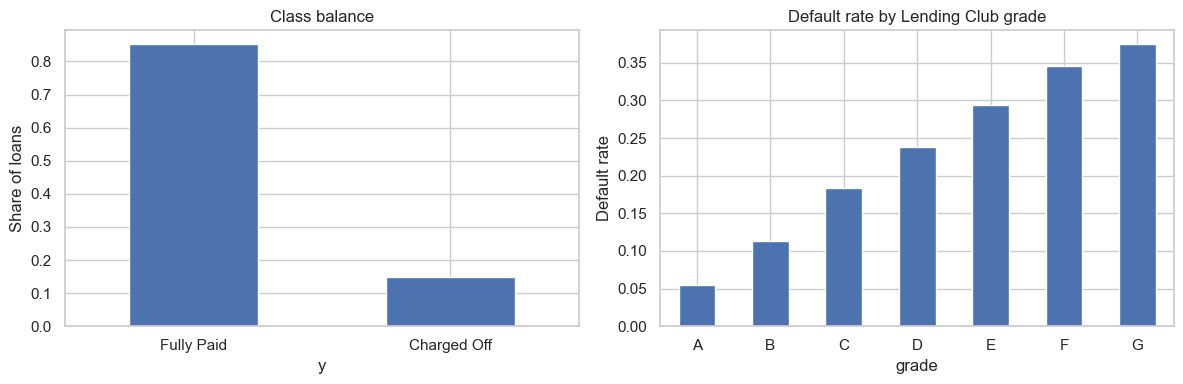

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["y"].value_counts(normalize=True).rename({0: "Fully Paid", 1: "Charged Off"}).plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Class balance", ylabel="Share of loans")
df.groupby("grade")["y"].mean().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Default rate by Lending Club grade", ylabel="Default rate")
plt.tight_layout()
plt.show()

**Interpretation:** The dataset is imbalanced, with approximately 85% of loans fully paid and 15% charged off. The default rate increases consistently from Lending Club grade A to G, indicating that the assigned grade is strongly associated with loan outcomes.

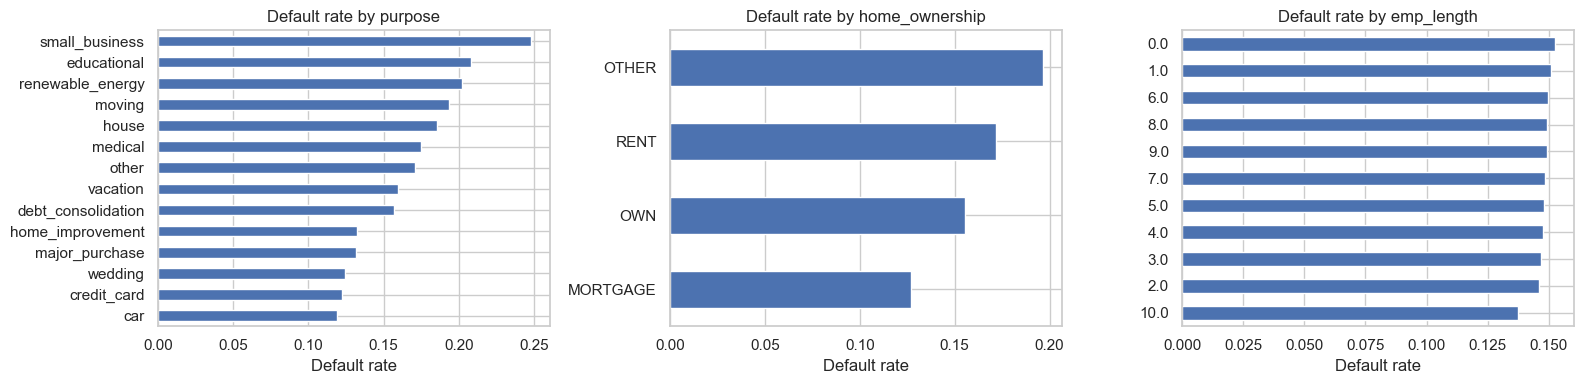

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["purpose", "home_ownership", "emp_length"]):
    df.groupby(col)["y"].mean().sort_values().plot.barh(ax=ax)
    ax.set(title=f"Default rate by {col}", xlabel="Default rate", ylabel="")
plt.tight_layout()
plt.show()

**Interpretation:** Default rates vary across loan purposes and home-ownership categories, while employment-length categories show relatively small differences. These patterns suggest that borrower and loan characteristics may provide useful predictive information.

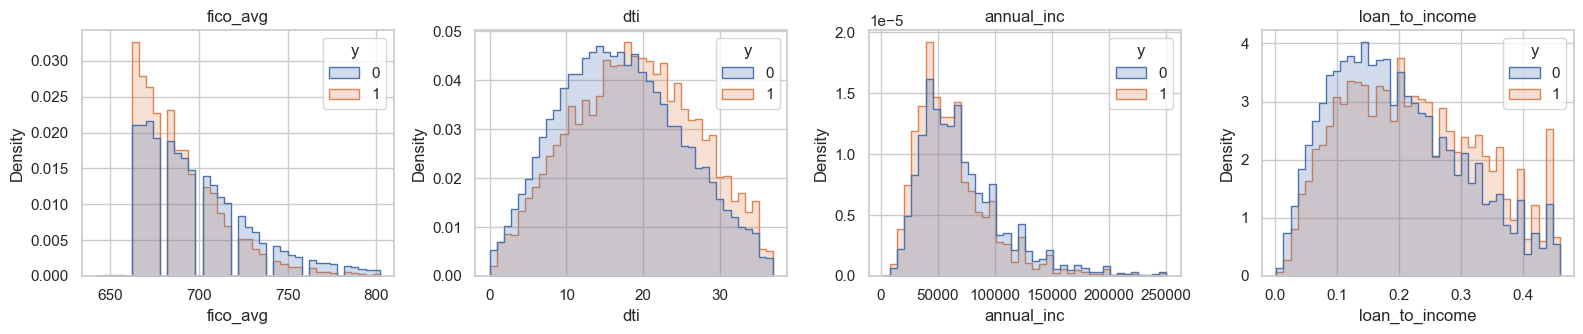

In [ ]:
sample = df.sample(50_000, random_state=RANDOM_STATE)
plot_cols = ["fico_avg", "dti", "annual_inc", "loan_to_income"]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(16, 3.5))
for ax, col in zip(axes, plot_cols):
    upper = sample[col].quantile(0.99)
    sns.histplot(data=sample[sample[col] <= upper], x=col, hue="y", stat="density",
                 common_norm=False, bins=40, element="step", ax=ax)
    ax.set(title=col)
plt.tight_layout()
plt.show()

**Interpretation:** The distributions of FICO score, debt-to-income ratio, annual income, and loan-to-income ratio overlap substantially between the two classes. This suggests that no single feature cleanly separates the outcomes, motivating multivariate modelling.

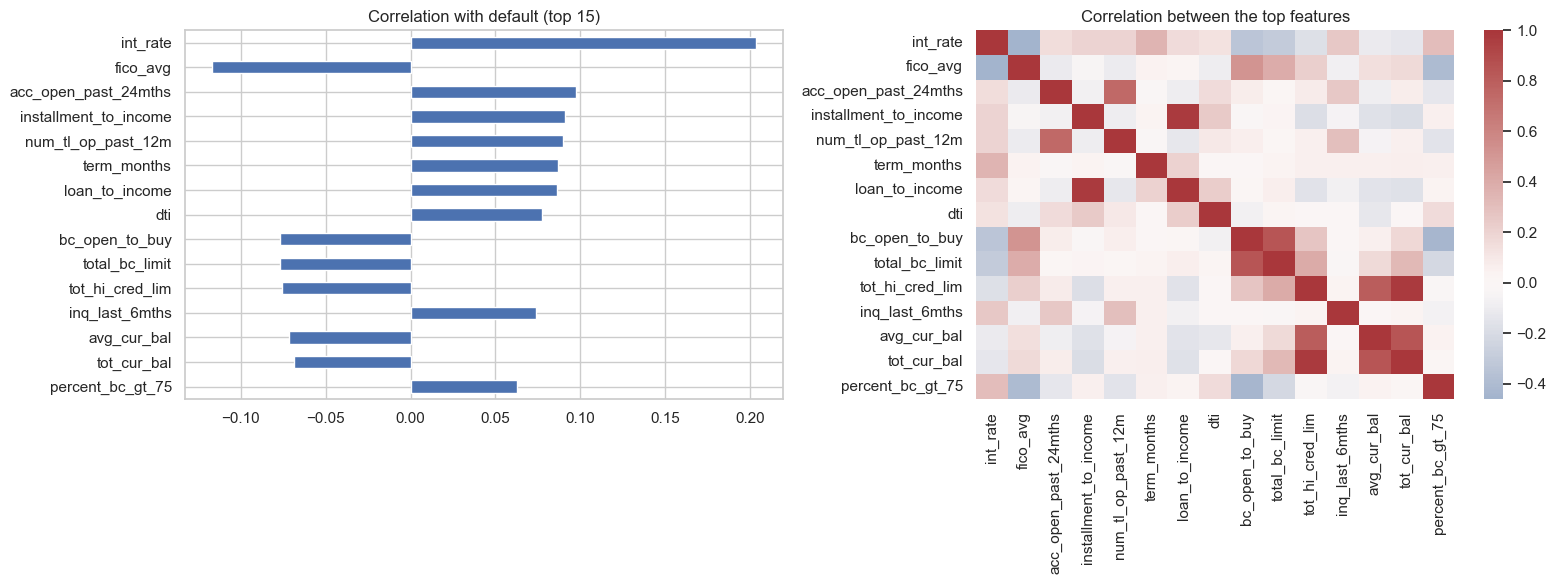

In [ ]:
numeric = df.select_dtypes("number").drop(columns=["y"])
corr_with_target = numeric.corrwith(df["y"]).sort_values(key=abs, ascending=False)
top = corr_with_target.head(15).index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr_with_target.head(15).plot.barh(ax=axes[0])
axes[0].set(title="Correlation with default (top 15)")
axes[0].invert_yaxis()
sns.heatmap(numeric[top].corr(), cmap="vlag", center=0, ax=axes[1])
axes[1].set(title="Correlation between the top features")
plt.tight_layout()
plt.show()

**Interpretation:** Interest rate has the strongest positive correlation with the target, while average FICO score has a negative correlation. The correlation heatmap also reveals relationships among credit-limit and balance features, highlighting potential redundancy; these associations do not imply causation.

## 3. Training

### 3.1 Chronological split

| Set | Issue years | Use |
|---|---|---|
| Train | 2007–2013 | fit the models |
| Validation | 2014 | compare models, tune hyper-parameters, choose threshold |
| Test | 2015 | evaluated **once**, at the very end |

Limitation: after 2013 only 36-month loans have matured, so validation and test contain no 60-month loans.

In [ ]:
year = df["issue_d"].dt.year
train, val, test = df[year <= 2013], df[year == 2014], df[year == 2015]

pd.DataFrame({
    "n_loans": [len(train), len(val), len(test)],
    "default_rate": [train["y"].mean(), val["y"].mean(), test["y"].mean()],
}, index=["train", "val", "test"]).round(3)

,n_loans,default_rate
train,230706,0.156
val,162570,0.137
test,283026,0.149


### 3.2 Feature sets

- **Model A (raw borrower data):** everything except Lending Club's pricing.
- **Model B (raw + LC pricing):** adds `grade`, `sub_grade`, `int_rate`, `installment`, `installment_to_income`.

In [ ]:
NOT_FEATURES = ["y", "issue_d"]
LC_PRICING = ["grade", "sub_grade", "int_rate", "installment", "installment_to_income"]

features_B = [c for c in df.columns if c not in NOT_FEATURES]
features_A = [c for c in features_B if c not in LC_PRICING]


def split_types(features):
    categorical = [c for c in features if df[c].dtype == object]
    numerical = [c for c in features if c not in categorical]
    return numerical, categorical


for name, feats in [("A", features_A), ("B", features_B)]:
    num, cat = split_types(feats)
    print(f"Model {name}: {len(feats)} features ({len(num)} numerical, {len(cat)} categorical: {cat})")

y_train, y_val, y_test = train["y"], val["y"], test["y"]

Model A: 67 features (61 numerical, 6 categorical: ['home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type'])
Model B: 72 features (64 numerical, 8 categorical: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type'])


### 3.3 Preprocessing pipelines


All preprocessing is fitted on training data only to prevent leakage.

- **Linear models:** outlier capping, median imputation, missing indicators, log transformation, standardisation, and one-hot encoding.
- **Tree models:** ordinal categorical encoding where required, with native missing-value handling when supported.

In [ ]:
SKEWED = ["annual_inc", "revol_bal", "loan_amnt", "tot_cur_bal", "tot_coll_amt", "avg_cur_bal",
          "bc_open_to_buy", "tot_hi_cred_lim", "total_bal_ex_mort", "total_bc_limit",
          "total_il_high_credit_limit", "total_rev_hi_lim", "delinq_amnt",
          "loan_to_income", "revol_bal_to_income", "installment_to_income"]


class QuantileCapper(BaseEstimator, TransformerMixin):
    # Caps every column at a high quantile. The caps are learned in fit(), i.e. on the training data only.

    def __init__(self, quantile=0.999):
        self.quantile = quantile

    def fit(self, X, y=None):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)   # all-missing column -> no cap
            caps = np.nanquantile(np.asarray(X, dtype=float), self.quantile, axis=0)
        self.caps_ = np.where(np.isnan(caps), np.inf, caps)
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.caps_)   # missing values stay missing


log1p_clipped = FunctionTransformer(lambda x: np.log1p(np.clip(x, 0, None)), feature_names_out="one-to-one")


def make_linear_preprocessor(features, cap=True):
    numerical, categorical = split_types(features)
    skewed = [c for c in numerical if c in SKEWED]
    other = [c for c in numerical if c not in SKEWED]
    capper = QuantileCapper(0.999) if cap else "passthrough"
    return ColumnTransformer([
        ("skewed", make_pipeline(capper, SimpleImputer(strategy="median", add_indicator=True),
                                 log1p_clipped, StandardScaler()), skewed),
        ("numeric", make_pipeline(capper, SimpleImputer(strategy="median", add_indicator=True),
                                  StandardScaler()), other),
        ("categorical", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                      OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                    min_frequency=0.001)), categorical),
    ])


def make_tree_preprocessor(features):
    numerical, categorical = split_types(features)
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                             encoded_missing_value=np.nan)
    preprocessor = ColumnTransformer([("categorical", encoder, categorical),
                                      ("numeric", "passthrough", numerical)])
    is_categorical = [True] * len(categorical) + [False] * len(numerical)
    return preprocessor, is_categorical

### 3.4 Evaluation helper and baselines

Metrics: **ROC-AUC** (ranking quality, threshold-free), **PR-AUC** (focuses on the rare default class; a random model scores ≈ the default rate) and the **Brier score** (quality of the predicted probabilities). Accuracy is not used: always predicting "Fully Paid" already gives ~86 %.

The **grade-only baseline** ranks loans by Lending Club's `sub_grade` (A1 = safest ... G5 = riskiest), with no training at all.

In [ ]:
results = []
predictions = {}   # (model name, split) -> predicted default probabilities, reused in section 4


def evaluate(name, y_true, proba, split="val"):
    scores = {
        "model": name, "split": split,
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba) if 0 <= proba.min() and proba.max() <= 1 else np.nan,
    }
    results[:] = [r for r in results if (r["model"], r["split"]) != (name, split)]   # safe to re-run cells
    results.append(scores)
    predictions[(name, split)] = proba
    return pd.DataFrame([scores]).round(4)


dummy = DummyClassifier(strategy="prior").fit(train[features_A], y_train)
display(evaluate("Dummy (prior)", y_val, dummy.predict_proba(val[features_A])[:, 1]))

subgrade_rank = {g: i for i, g in enumerate(sorted(df["sub_grade"].unique()))}
display(evaluate("LC sub_grade only", y_val, val["sub_grade"].map(subgrade_rank).to_numpy()))
display(evaluate("LC int_rate only", y_val, val["int_rate"].to_numpy()))

,model,split,roc_auc,pr_auc,brier
0,Dummy (prior),val,0.5,0.1373,0.1188


,model,split,roc_auc,pr_auc,brier
0,LC sub_grade only,val,0.6596,0.2161,NaN


,model,split,roc_auc,pr_auc,brier
0,LC int_rate only,val,0.6577,0.2161,NaN


### 3.5 Logistic regression (models A and B)

`class_weight="balanced"` makes the model pay as much attention to the minority class as to the majority class. It changes the calibration of the probabilities (they are no longer true default probabilities), which we will discuss in the evaluation.

In [ ]:
models = {}
for name, feats in [("A", features_A), ("B", features_B)]:
    model = make_pipeline(
        make_linear_preprocessor(feats),
        LogisticRegression(class_weight="balanced", max_iter=2000),
    )
    model.fit(train[feats], y_train)
    models[f"LogReg {name}"] = (model, feats)
    display(evaluate(f"LogReg {name}", y_val, model.predict_proba(val[feats])[:, 1]))

,model,split,roc_auc,pr_auc,brier
0,LogReg A,val,0.6755,0.2359,0.1996


,model,split,roc_auc,pr_auc,brier
0,LogReg B,val,0.6839,0.2421,0.1929


**Does the capping help?** We re-train the same two logistic regressions *without* the capping step and compare.

In [ ]:
for name, feats in [("A", features_A), ("B", features_B)]:
    model = make_pipeline(
        make_linear_preprocessor(feats, cap=False),
        LogisticRegression(class_weight="balanced", max_iter=2000),
    )
    model.fit(train[feats], y_train)
    evaluate(f"LogReg {name}, no capping", y_val, model.predict_proba(val[feats])[:, 1])

capping_rows = ["LogReg A, no capping", "LogReg A", "LogReg B, no capping", "LogReg B"]
pd.DataFrame(results).set_index("model").loc[capping_rows, ["roc_auc", "pr_auc", "brier"]].round(4)

,roc_auc,pr_auc,brier
model,,,
"LogReg A, no capping",0.6753,0.2360,0.1994
LogReg A,0.6755,0.2359,0.1996
"LogReg B, no capping",0.6837,0.2420,0.1927
LogReg B,0.6839,0.2421,0.1929


**Observation.** Capping changes the validation ROC-AUC by only +0.0002 (A: 0.6753 → 0.6755; B: 0.6837 → 0.6839).
The training years contain almost no extreme values and the `log1p` transform already shrinks large amounts, so there is little to fix in 2014.
We keep the capping anyway: it costs nothing and protects the linear model against impossible values such as `dti` = 999 in the 2015 test year.

### 3.6 Histogram gradient boosting (models A and B)

In [ ]:
for name, feats in [("A", features_A), ("B", features_B)]:
    preprocessor, is_categorical = make_tree_preprocessor(feats)
    model = make_pipeline(
        preprocessor,
        HistGradientBoostingClassifier(categorical_features=is_categorical, learning_rate=0.05,
                                       max_iter=500, early_stopping=True,
                                       random_state=RANDOM_STATE),
    )
    model.fit(train[feats], y_train)
    models[f"HGB {name}"] = (model, feats)
    display(evaluate(f"HGB {name}", y_val, model.predict_proba(val[feats])[:, 1]))

,model,split,roc_auc,pr_auc,brier
0,HGB A,val,0.6784,0.2393,0.1128


,model,split,roc_auc,pr_auc,brier
0,HGB B,val,0.6865,0.246,0.1123


### 3.7 Random forest (models A and B)

A bagging ensemble, to compare with boosting. Categories are ordinal-encoded (an approximation for nominal variables that trees tolerate well) and missing values are imputed, because `RandomForestClassifier` needs complete inputs. Trees are kept fairly shallow (`min_samples_leaf=50`) and each tree sees half of the rows (`max_samples=0.5`) to keep training time reasonable.

In [ ]:
def make_rf(features):
    preprocessor, _ = make_tree_preprocessor(features)
    return make_pipeline(
        preprocessor,
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt",
                               max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE),
    )


for name, feats in [("A", features_A), ("B", features_B)]:
    model = make_rf(feats).fit(train[feats], y_train)
    models[f"RF {name}"] = (model, feats)
    display(evaluate(f"RF {name}", y_val, model.predict_proba(val[feats])[:, 1]))

,model,split,roc_auc,pr_auc,brier
0,RF A,val,0.6761,0.2379,0.1133


,model,split,roc_auc,pr_auc,brier
0,RF B,val,0.6848,0.2446,0.1125


### 3.8 XGBoost and LightGBM (models A and B)


We compare XGBoost and LightGBM with scikit-learn's gradient boosting using the same feature sets and comparable initial settings. Both achieve validation ROC-AUC scores of approximately 0.693 on Model B, motivating further tuning.

In [ ]:
def make_xgb(features):
    preprocessor, _ = make_tree_preprocessor(features)
    return make_pipeline(
        preprocessor,
        XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, min_child_weight=50,
                      subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist",
                      n_jobs=-1, random_state=RANDOM_STATE),
    )


def make_lgbm(features):
    preprocessor, _ = make_tree_preprocessor(features)
    return make_pipeline(
        preprocessor,
        LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                       n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
    )


for family, factory in [("XGBoost", make_xgb), ("LightGBM", make_lgbm)]:
    for name, feats in [("A", features_A), ("B", features_B)]:
        model = factory(feats).fit(train[feats], y_train)
        models[f"{family} {name}"] = (model, feats)
        display(evaluate(f"{family} {name}", y_val, model.predict_proba(val[feats])[:, 1]))

,model,split,roc_auc,pr_auc,brier
0,XGBoost A,val,0.6854,0.2461,0.1124


,model,split,roc_auc,pr_auc,brier
0,XGBoost B,val,0.6927,0.2524,0.1119


,model,split,roc_auc,pr_auc,brier
0,LightGBM A,val,0.6861,0.2464,0.1123


,model,split,roc_auc,pr_auc,brier
0,LightGBM B,val,0.6925,0.2524,0.1119


**Observation.** Without any tuning, XGBoost and LightGBM reach the same validation ROC-AUC (0.693 on set B, 0.685–0.686 on set A), slightly above scikit-learn's gradient boosting (0.687). For a fair comparison, all three are tuned with the same protocol in the next section.
A likely reason is their random row and column subsampling, which acts as extra regularisation; we did not test this further. The gain is small (+0.005), consistent with the rest of our results: the choice of model matters much less than the information in the data.

### 3.9 Hyper-parameter tuning (HistGradientBoosting, XGBoost, LightGBM)

We perform 20 random-search trials per boosting implementation using the same temporal validation protocol: training on 2007–2013 and validating on 2014. The best parameters found for Model B are reused for Model A to ensure a fair feature-set comparison.

Tuning produces only marginal improvements, with tuned LightGBM achieving the highest Model B validation ROC-AUC of 0.6932.

In [ ]:
train_val = pd.concat([train, val])
fold = np.r_[np.full(len(train), -1), np.zeros(len(val))]   # -1 = always in training, 0 = validation fold

preprocessor, is_categorical = make_tree_preprocessor(features_B)
search = RandomizedSearchCV(
    make_pipeline(preprocessor,
                  HistGradientBoostingClassifier(categorical_features=is_categorical, max_iter=1000,
                                                 early_stopping=True, random_state=RANDOM_STATE)),
    param_distributions={
        "histgradientboostingclassifier__learning_rate": loguniform(0.01, 0.2),
        "histgradientboostingclassifier__max_leaf_nodes": randint(8, 128),
        "histgradientboostingclassifier__min_samples_leaf": randint(20, 1000),
        "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    },
    n_iter=20, scoring="roc_auc", cv=PredefinedSplit(fold), refit=False, random_state=RANDOM_STATE,
)
search.fit(train_val[features_B], train_val["y"])

best_params = search.best_params_
print(f"Best validation ROC-AUC: {search.best_score_:.4f}")
print({k.split("__")[1]: round(v, 4) for k, v in best_params.items()})
(pd.DataFrame(search.cv_results_)
   .sort_values("rank_test_score")
   .filter(regex="param_|mean_test_score")
   .head(5).round(4))

Best validation ROC-AUC: 0.6880
{'l2_regularization': 0.5408, 'learning_rate': 0.0622, 'max_leaf_nodes': 15, 'min_samples_leaf': 962}


,param_histgradientboostingclassifier__l2_regularization,param_histgradientboostingclassifier__learning_rate,param_histgradientboostingclassifier__max_leaf_nodes,param_histgradientboostingclassifier__min_samples_leaf,mean_test_score
13,0.540822,0.062176,15,962,0.6880
9,0.114009,0.058986,10,504,0.6875
16,0.186553,0.010983,25,749,0.6871
10,0.269265,0.016667,46,293,0.6868
4,2.136833,0.018891,71,975,0.6868


In [ ]:
def make_tuned_hgb(features, class_weight=None):
    preprocessor, is_categorical = make_tree_preprocessor(features)
    model = make_pipeline(
        preprocessor,
        HistGradientBoostingClassifier(categorical_features=is_categorical, max_iter=1000,
                                       early_stopping=True, class_weight=class_weight,
                                       random_state=RANDOM_STATE),
    )
    return model.set_params(**best_params)


for name, feats in [("A", features_A), ("B", features_B)]:
    model = make_tuned_hgb(feats).fit(train[feats], y_train)
    models[f"HGB {name} tuned"] = (model, feats)
    display(evaluate(f"HGB {name} tuned", y_val, model.predict_proba(val[feats])[:, 1]))

,model,split,roc_auc,pr_auc,brier
0,HGB A tuned,val,0.6815,0.2418,0.1126


,model,split,roc_auc,pr_auc,brier
0,HGB B tuned,val,0.688,0.2485,0.1122


#### XGBoost and LightGBM

Same protocol as above. The search ranges cover the usual settings of each library: number of trees, learning rate, tree size, minimum data per leaf, row and column subsampling, and L2 regularisation.

In [ ]:
def tune(estimator, param_distributions):
    # Same protocol as for HistGradientBoosting: 20 candidates, trained on 2007-2013, scored on 2014.
    search = RandomizedSearchCV(estimator, param_distributions, n_iter=20, scoring="roc_auc",
                                cv=PredefinedSplit(fold), refit=False, random_state=RANDOM_STATE)
    return search.fit(train_val[features_B], train_val["y"])


xgb_search = tune(make_xgb(features_B), {
    "xgbclassifier__n_estimators": randint(200, 800),
    "xgbclassifier__learning_rate": loguniform(0.01, 0.2),
    "xgbclassifier__max_depth": randint(3, 9),
    "xgbclassifier__min_child_weight": loguniform(1, 500),
    "xgbclassifier__subsample": uniform(0.5, 0.5),          # 0.5 - 1.0
    "xgbclassifier__colsample_bytree": uniform(0.4, 0.6),   # 0.4 - 1.0
    "xgbclassifier__reg_lambda": loguniform(0.1, 100),
})
print(f"XGBoost  - best validation ROC-AUC: {xgb_search.best_score_:.4f}")
print({k.split("__")[1]: round(v, 4) for k, v in xgb_search.best_params_.items()})

XGBoost  - best validation ROC-AUC: 0.6922
{'colsample_bytree': 0.8995, 'learning_rate': 0.0189, 'max_depth': 6, 'min_child_weight': 3.1261, 'n_estimators': 659, 'reg_lambda': 6.8385, 'subsample': 0.5035}


In [ ]:
lgbm_search = tune(make_lgbm(features_B), {
    "lgbmclassifier__n_estimators": randint(200, 800),
    "lgbmclassifier__learning_rate": loguniform(0.01, 0.2),
    "lgbmclassifier__num_leaves": randint(8, 128),
    "lgbmclassifier__min_child_samples": randint(20, 1000),
    "lgbmclassifier__subsample": uniform(0.5, 0.5),         # 0.5 - 1.0
    "lgbmclassifier__colsample_bytree": uniform(0.4, 0.6),  # 0.4 - 1.0
    "lgbmclassifier__reg_lambda": loguniform(1e-3, 10),
})
print(f"LightGBM - best validation ROC-AUC: {lgbm_search.best_score_:.4f}")
print({k.split("__")[1]: round(v, 4) for k, v in lgbm_search.best_params_.items()})

LightGBM - best validation ROC-AUC: 0.6932
{'colsample_bytree': 0.767, 'learning_rate': 0.0102, 'min_child_samples': 876, 'n_estimators': 760, 'num_leaves': 98, 'reg_lambda': 0.2802, 'subsample': 0.5697}


In [ ]:
def make_tuned_xgb(features):
    return make_xgb(features).set_params(**xgb_search.best_params_)


def make_tuned_lgbm(features):
    return make_lgbm(features).set_params(**lgbm_search.best_params_)


for family, factory in [("XGBoost", make_tuned_xgb), ("LightGBM", make_tuned_lgbm)]:
    for name, feats in [("A", features_A), ("B", features_B)]:
        model = factory(feats).fit(train[feats], y_train)
        models[f"{family} {name} tuned"] = (model, feats)
        evaluate(f"{family} {name} tuned", y_val, model.predict_proba(val[feats])[:, 1])

scores = pd.DataFrame(results).query("split == 'val'").set_index("model")["roc_auc"]
tuning_gain = {}
for family, short in [("HistGradientBoosting", "HGB"), ("XGBoost", "XGBoost"), ("LightGBM", "LightGBM")]:
    tuning_gain[family] = {f"set {fs}, {state}": scores[f"{short} {fs}{suffix}"]
                           for fs in ["A", "B"] for state, suffix in [("untuned", ""), ("tuned", " tuned")]}
pd.DataFrame(tuning_gain).T.round(4)

,"set A, untuned","set A, tuned","set B, untuned","set B, tuned"
HistGradientBoosting,0.6784,0.6815,0.6865,0.6880
XGBoost,0.6854,0.6856,0.6927,0.6922
LightGBM,0.6861,0.6870,0.6925,0.6932


**Observation.** Tuning brings very little, and the three implementations end up within 0.005 of each other on set B:

- HistGradientBoosting: +0.0015 (0.6865 → 0.6880);
- LightGBM: +0.0007 (0.6925 → 0.6932);
- XGBoost: the search did **not** find better settings than the ones we started from (0.6922 tuned vs 0.6927 untuned). Random search only tries 20 combinations, and the starting settings were already good.

This confirms that the choice and tuning of the model matter much less than the information in the data. We keep the **tuned** versions for the final choice, so that all three are selected by exactly the same procedure.

### 3.10 Handling the class imbalance

Only ~15 % of loans default. We compare three common strategies on feature set B:

- **No weighting** (and choose a decision threshold later, section 4.2),
- **`class_weight="balanced"`** (errors on defaults cost ~6× more during training),
- **SMOTE** (synthetic oversampling of defaults; inside an `imblearn` pipeline so it is only applied to the training data).

We report the ranking metrics (ROC-AUC, PR-AUC), the calibration (Brier score) and the recall obtained with the default 0.5 threshold.

In [ ]:
imbalance_variants = {
    "LogReg B, no weighting": make_pipeline(make_linear_preprocessor(features_B),
                                            LogisticRegression(max_iter=2000)),
    "LogReg B, SMOTE": make_imb_pipeline(make_linear_preprocessor(features_B),
                                         SMOTE(random_state=RANDOM_STATE),
                                         LogisticRegression(max_iter=2000)),
    "HGB B tuned, balanced": make_tuned_hgb(features_B, class_weight="balanced"),
}
for name, model in imbalance_variants.items():
    model.fit(train[features_B], y_train)
    models[name] = (model, features_B)
    evaluate(name, y_val, model.predict_proba(val[features_B])[:, 1])

comparison = ["LogReg B, no weighting", "LogReg B", "LogReg B, SMOTE", "HGB B tuned", "HGB B tuned, balanced"]
imbalance_table = pd.DataFrame(results).query("split == 'val' and model in @comparison").set_index("model").loc[comparison]
imbalance_table["recall@0.5"] = [recall_score(y_val, predictions[(m, "val")] >= 0.5) for m in comparison]
imbalance_table.rename(index={"LogReg B": "LogReg B, balanced"}).round(4)

,split,roc_auc,pr_auc,brier,recall@0.5
model,,,,,
"LogReg B, no weighting",val,0.6846,0.2435,0.1125,0.0023
"LogReg B, balanced",val,0.6839,0.2421,0.1929,0.5140
"LogReg B, SMOTE",val,0.6768,0.2387,0.1802,0.4444
HGB B tuned,val,0.6880,0.2485,0.1122,0.0003
"HGB B tuned, balanced",val,0.6873,0.2470,0.1905,0.5309


**Observation.** Re-weighting and SMOTE do **not** improve the ranking of loans (logistic regression: ROC-AUC 0.685 unweighted, 0.684 balanced, 0.677 SMOTE; boosting: 0.688 vs 0.687).
What they change is the scale of the probabilities: recall at the 0.5 threshold jumps from ~0 % to ~50 %, but the Brier score degrades from 0.112 to ~0.19 because the predicted probabilities are inflated (see the calibration plot in 4.3).
The same recall can be obtained from the unweighted model simply by **lowering the threshold** (section 4.2), while keeping probabilities that mean something.
We therefore keep the **unweighted** models.

### 3.11 Choosing the final model

Rule, decided before looking at the test set: among the three **tuned** boosting implementations, the one with the best **validation** ROC-AUC on feature set B becomes the final model.
If it beats our tuned HistGradientBoosting by less than 0.002 (noise level), we keep HistGradientBoosting, because it is native to scikit-learn.

In [ ]:
CANDIDATES = {   # family -> (model A name, model B name, factory used for the final refit)
    "HGB tuned": ("HGB A tuned", "HGB B tuned", make_tuned_hgb),
    "XGBoost tuned": ("XGBoost A tuned", "XGBoost B tuned", make_tuned_xgb),
    "LightGBM tuned": ("LightGBM A tuned", "LightGBM B tuned", make_tuned_lgbm),
}
val_auc = pd.Series({family: roc_auc_score(y_val, predictions[(names[1], "val")])
                     for family, names in CANDIDATES.items()})
best_family = val_auc.idxmax()
final_family = best_family if val_auc[best_family] - val_auc["HGB tuned"] >= 0.002 else "HGB tuned"
FINAL_A, FINAL_B, make_final = CANDIDATES[final_family]

print(f"Final model family: {final_family}  ->  {FINAL_A} / {FINAL_B}")
val_auc.round(4).to_frame("validation ROC-AUC (feature set B)")

Final model family: LightGBM tuned  ->  LightGBM A tuned / LightGBM B tuned


,validation ROC-AUC (feature set B)
HGB tuned,0.6880
XGBoost tuned,0.6922
LightGBM tuned,0.6932


**Decision.** Tuned LightGBM (0.6932) beats tuned HistGradientBoosting (0.6880) by 0.0052, above our 0.002 margin, so **tuned LightGBM is our final model** for section 4.
Tuned XGBoost is practically tied (0.6922): the gap between the two libraries (0.001) is far below what we could call a real difference.

## 4. Evaluation

### 4.1 Model comparison on the validation set (2014)

In [ ]:
pd.DataFrame(results).query("split == 'val'").set_index("model").drop(columns="split").round(4)

,roc_auc,pr_auc,brier
model,,,
Dummy (prior),0.5000,0.1373,0.1188
LC sub_grade only,0.6596,0.2161,NaN
LC int_rate only,0.6577,0.2161,NaN
LogReg A,0.6755,0.2359,0.1996
LogReg B,0.6839,0.2421,0.1929
"LogReg A, no capping",0.6753,0.2360,0.1994
"LogReg B, no capping",0.6837,0.2420,0.1927
HGB A,0.6784,0.2393,0.1128
HGB B,0.6865,0.2460,0.1123


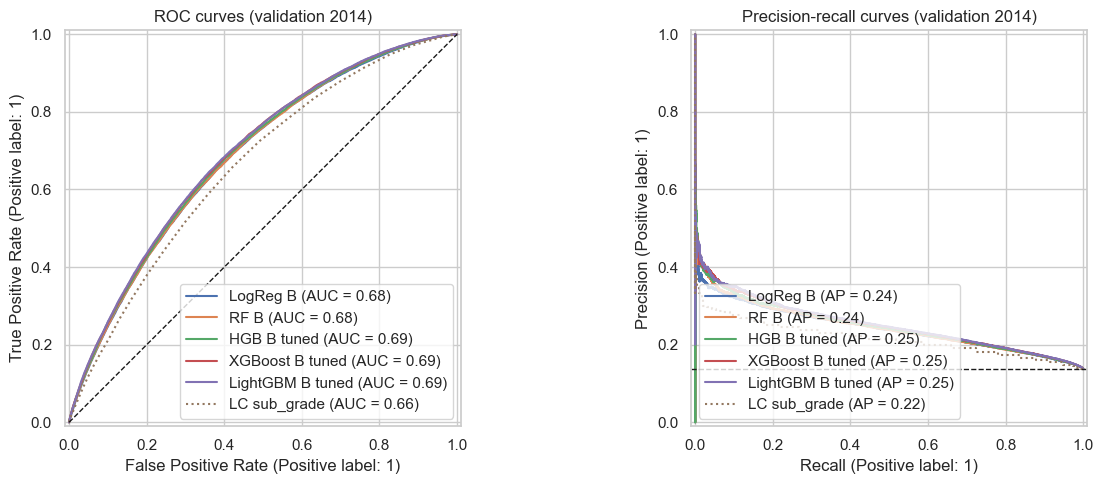

In [ ]:
KEY_MODELS = ["LogReg B", "RF B", "HGB B tuned", "XGBoost B tuned", "LightGBM B tuned"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in KEY_MODELS:
    proba = predictions[(name, "val")]
    RocCurveDisplay.from_predictions(y_val, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, proba, name=name, ax=axes[1])
rank = val["sub_grade"].map(subgrade_rank)
RocCurveDisplay.from_predictions(y_val, rank, name="LC sub_grade", ax=axes[0], ls=":")
PrecisionRecallDisplay.from_predictions(y_val, rank, name="LC sub_grade", ax=axes[1], ls=":")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves (validation 2014)")
axes[1].axhline(y_val.mean(), color="k", ls="--", lw=1)
axes[1].set(title="Precision-recall curves (validation 2014)")
plt.tight_layout()
plt.show()

### 4.2 Choosing a decision threshold

To accept or reject a loan we need a threshold on the predicted probability. The two errors do not cost the same:

- **missed default** (false negative): the investor loses a large part of the principal — we assume **65 %** (charged-off loans usually repay part of the principal before defaulting, and some is recovered);
- **rejected good loan** (false positive): the investor only loses the interest they would have earned — we assume **15 %** of the principal (≈ 13 % yearly rate over 36 months, net of fees).



With well-calibrated probabilities, decision theory gives the optimal threshold directly: reject when $p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{0.15}{0.80} \approx 0.19$.
We also search the threshold empirically on the 2014 validation set and keep it fixed for the test set.

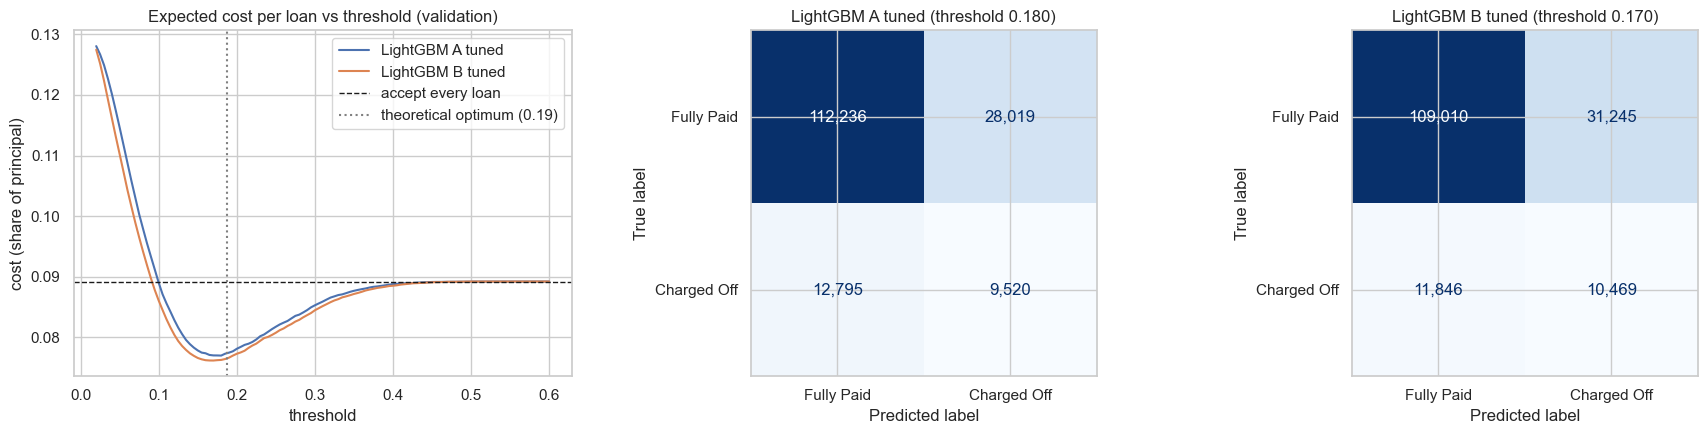

,threshold,precision,recall,share rejected,cost per loan,saving vs accept-all
LightGBM A tuned,0.18,0.254,0.427,0.231,0.077,0.137
LightGBM B tuned,0.17,0.251,0.469,0.257,0.076,0.146


In [ ]:
COST_MISSED_DEFAULT = 0.65   # share of the principal lost when a funded loan is charged off (assumption)
COST_REJECTED_GOOD = 0.15    # interest forgone when a good loan is rejected (assumption)


def expected_cost(y_true, proba, threshold):
    # Average cost per loan (in share of principal) if we reject every loan with proba >= threshold.
    flagged = proba >= threshold
    missed_defaults = ((y_true == 1) & ~flagged).sum()
    rejected_good = ((y_true == 0) & flagged).sum()
    return (COST_MISSED_DEFAULT * missed_defaults + COST_REJECTED_GOOD * rejected_good) / len(y_true)


grid = np.linspace(0.02, 0.60, 117)
bayes_threshold = COST_REJECTED_GOOD / (COST_REJECTED_GOOD + COST_MISSED_DEFAULT)
accept_all_cost = COST_MISSED_DEFAULT * y_val.mean()

thresholds = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in [FINAL_A, FINAL_B]:
    costs = [expected_cost(y_val.to_numpy(), predictions[(name, "val")], t) for t in grid]
    thresholds[name] = grid[np.argmin(costs)]
    axes[0].plot(grid, costs, label=name)
axes[0].axhline(accept_all_cost, color="k", ls="--", lw=1, label="accept every loan")
axes[0].axvline(bayes_threshold, color="grey", ls=":", label=f"theoretical optimum ({bayes_threshold:.2f})")
axes[0].set(title="Expected cost per loan vs threshold (validation)", xlabel="threshold",
            ylabel="cost (share of principal)")
axes[0].legend()

for ax, name in zip(axes[1:], [FINAL_A, FINAL_B]):
    ConfusionMatrixDisplay.from_predictions(y_val, predictions[(name, "val")] >= thresholds[name],
                                            display_labels=["Fully Paid", "Charged Off"],
                                            cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set(title=f"{name} (threshold {thresholds[name]:.3f})")
plt.tight_layout()
plt.show()


def decision_summary(y_true, proba, threshold):
    flagged = proba >= threshold
    cost = expected_cost(y_true.to_numpy(), proba, threshold)
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, flagged),
        "recall": recall_score(y_true, flagged),
        "share rejected": flagged.mean(),
        "cost per loan": cost,
        "saving vs accept-all": 1 - cost / (COST_MISSED_DEFAULT * y_true.mean()),
    }


pd.DataFrame({name: decision_summary(y_val, predictions[(name, "val")], thresholds[name])
              for name in thresholds}).T.round(3)

### 4.3 Calibration

In credit, the probability itself matters (it is used to price the loan). A calibration curve compares the predicted probability with the observed default rate.

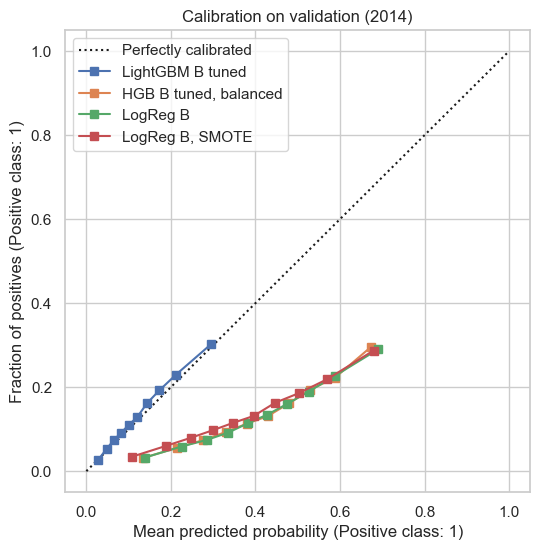

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in [FINAL_B, "HGB B tuned, balanced", "LogReg B", "LogReg B, SMOTE"]:
    CalibrationDisplay.from_predictions(y_val, predictions[(name, "val")], n_bins=10,
                                        strategy="quantile", name=name, ax=ax)
ax.set(title="Calibration on validation (2014)")
ax.legend(loc="upper left")
plt.show()

### 4.4 Which features matter?

**Permutation importance:** shuffle one column and measure how much the validation ROC-AUC drops. It is computed on the raw input columns (before one-hot encoding), on a 30k-loan sample of the validation set to keep it fast.

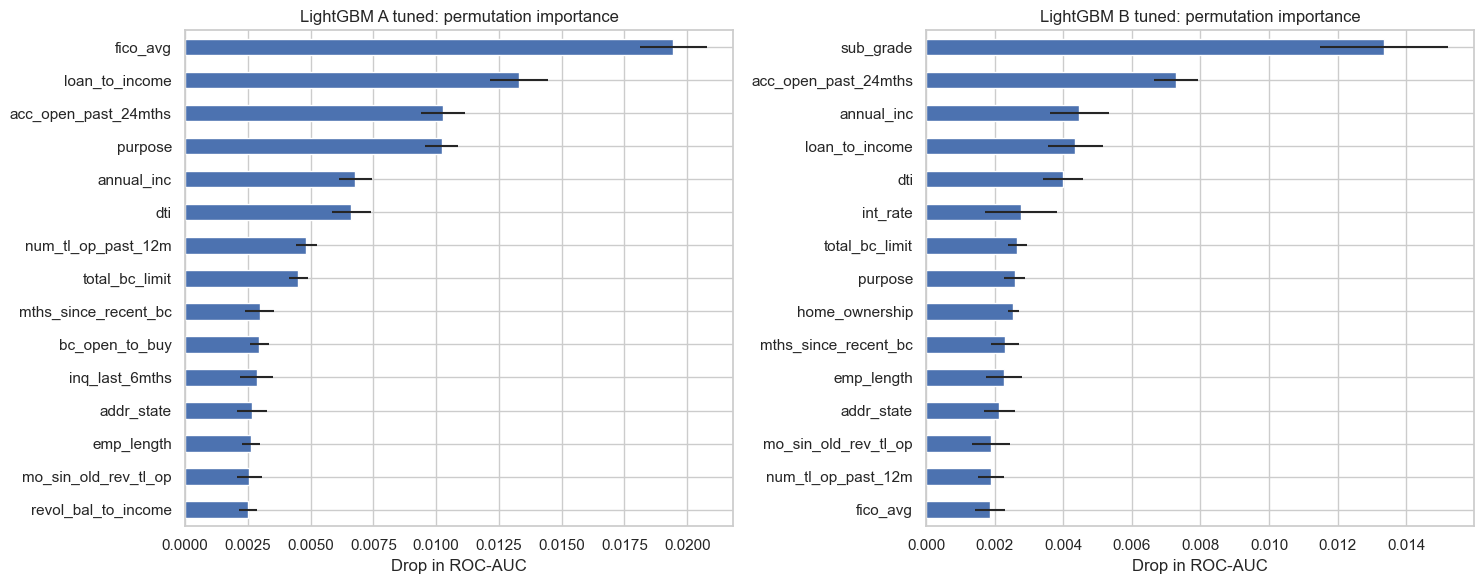

In [ ]:
sample = val.sample(30_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, [FINAL_A, FINAL_B]):
    model, feats = models[name]
    result = permutation_importance(model, sample[feats], sample["y"], scoring="roc_auc",
                                    n_repeats=5, random_state=RANDOM_STATE)
    importance = (pd.DataFrame({"mean": result.importances_mean, "std": result.importances_std}, index=feats)
                    .sort_values("mean").tail(15))
    importance["mean"].plot.barh(xerr=importance["std"], ax=ax)
    ax.set(title=f"{name}: permutation importance", xlabel="Drop in ROC-AUC")
plt.tight_layout()
plt.show()

### 4.5 Do we add information beyond Lending Club's grade?

If the model only re-discovered the grade, it would be useless *inside* a grade. We compute the ROC-AUC separately within each grade:
a value above 0.5 means the model can still separate good and bad borrowers that Lending Club put in the same risk class.

In [ ]:
rows = []
for grade, group in val.groupby("grade"):
    in_grade = (val["grade"] == grade).to_numpy()
    rows.append({
        "grade": grade,
        "n_loans": len(group),
        "default_rate": group["y"].mean(),
        "AUC sub_grade": roc_auc_score(group["y"], group["sub_grade"].map(subgrade_rank)),
        f"AUC {FINAL_A}": roc_auc_score(group["y"], predictions[(FINAL_A, "val")][in_grade]),
        f"AUC {FINAL_B}": roc_auc_score(group["y"], predictions[(FINAL_B, "val")][in_grade]),
    })
pd.DataFrame(rows).set_index("grade").round(3)

,n_loans,default_rate,AUC sub_grade,AUC LightGBM A tuned,AUC LightGBM B tuned
grade,,,,,
A,35333,0.054,0.590,0.657,0.661
B,53460,0.107,0.549,0.629,0.627
C,44042,0.172,0.534,0.614,0.615
D,20510,0.222,0.513,0.601,0.604
E,7066,0.270,0.512,0.602,0.602
F,1980,0.295,0.543,0.626,0.633
G,179,0.363,0.514,0.567,0.613


**Observation.** Inside every grade, the 5 sub-grades only weakly separate good and bad loans (AUC 0.51–0.59), whereas our models reach 0.60–0.66 (0.57–0.61 for the small grade G).
So the model is not just re-learning Lending Club's grade: it ranks borrowers *within* a risk class better than Lending Club's own sub-grade does.
Permutation importance (4.4) tells the same story: without the grade, Model A relies on the FICO score, loan-to-income, purpose and recent credit activity (`acc_open_past_24mths`); once the sub-grade is available (Model B) it dominates, because it already summarises the FICO score.

### 4.6 Error analysis

Where does the model fail? We look at performance per loan purpose, and compare the defaults the model **missed** (false negatives) with the ones it **caught** (true positives).

In [ ]:
name = FINAL_B
analysis = val.assign(proba=predictions[(name, "val")])
analysis["flagged"] = analysis["proba"] >= thresholds[name]


def group_summary(g):
    return pd.Series({
        "n_loans": len(g),
        "default_rate": g["y"].mean(),
        "mean_predicted": g["proba"].mean(),
        "recall": g.loc[g["y"] == 1, "flagged"].mean(),
        "roc_auc": roc_auc_score(g["y"], g["proba"]) if g["y"].nunique() == 2 else np.nan,
    })


by_purpose = analysis.groupby("purpose")[["y", "proba", "flagged"]].apply(group_summary).astype({"n_loans": int}).sort_values("n_loans", ascending=False)
display(by_purpose.head(8).round(3))

defaults = analysis[analysis["y"] == 1]
profile_cols = ["fico_avg", "int_rate", "dti", "annual_inc", "loan_to_income", "credit_hist_years", "inq_last_6mths"]
(defaults.groupby(defaults["flagged"].map({True: "caught (TP)", False: "missed (FN)"}))[profile_cols]
         .median().T.round(2))

,n_loans,default_rate,mean_predicted,recall,roc_auc
purpose,,,,,
debt_consolidation,94822,0.144,0.133,0.496,0.688
credit_card,40100,0.116,0.100,0.321,0.703
home_improvement,8654,0.119,0.120,0.446,0.710
other,8252,0.153,0.162,0.599,0.667
major_purchase,2888,0.135,0.123,0.467,0.700
medical,1885,0.170,0.147,0.505,0.646
small_business,1634,0.225,0.216,0.780,0.616
car,1516,0.115,0.109,0.371,0.715


flagged,caught (TP),missed (FN)
fico_avg,677.00,687.00
int_rate,16.24,12.49
dti,21.47,16.88
annual_inc,44000.00,64600.00
loan_to_income,0.25,0.17
credit_hist_years,13.25,15.00
inq_last_6mths,1.00,0.00


**Observation.** The defaults the model misses look like *good* borrowers: higher FICO, lower interest rate (≈ 12 % vs ≈ 16 %), lower DTI, higher income (≈ \$65k vs \$44k), longer credit history and no recent credit inquiries.
Nothing in the application separates them from borrowers who repay; their default is probably caused by events after the loan was issued (job loss, illness...).
This is the irreducible part of the problem and explains why no honest model goes far beyond ROC-AUC ≈ 0.70.
Performance is fairly uniform across purposes; `small_business` and `medical` loans are riskier and slightly harder to rank.

### 4.7 Final evaluation on the test set (2015)

The final models are refitted on **train + validation (2007–2014)**, so they learn from the most recent data available, and evaluated **once** on 2015.
The thresholds chosen in 4.2 are kept unchanged.

In [ ]:
final_models = {}
for name, feats in [(FINAL_A, features_A), (FINAL_B, features_B)]:
    model = make_final(feats).fit(train_val[feats], train_val["y"])
    final_models[name] = model
    evaluate(name, y_test, model.predict_proba(test[feats])[:, 1], split="test")
evaluate("LC sub_grade only", y_test, test["sub_grade"].map(subgrade_rank).to_numpy(), split="test")

summary = (pd.DataFrame(results)
             .loc[lambda r: r["model"].isin(["LC sub_grade only", FINAL_A, FINAL_B])]
             .pivot(index="model", columns="split", values=["roc_auc", "pr_auc"]))
summary.round(4)

roc_auc          pr_auc        
split                test     val    test     val
model                                            
LC sub_grade only  0.6787  0.6596  0.2507  0.2161
LightGBM A tuned   0.6990  0.6870  0.2790  0.2472
LightGBM B tuned   0.7089  0.6932  0.2898  0.2532

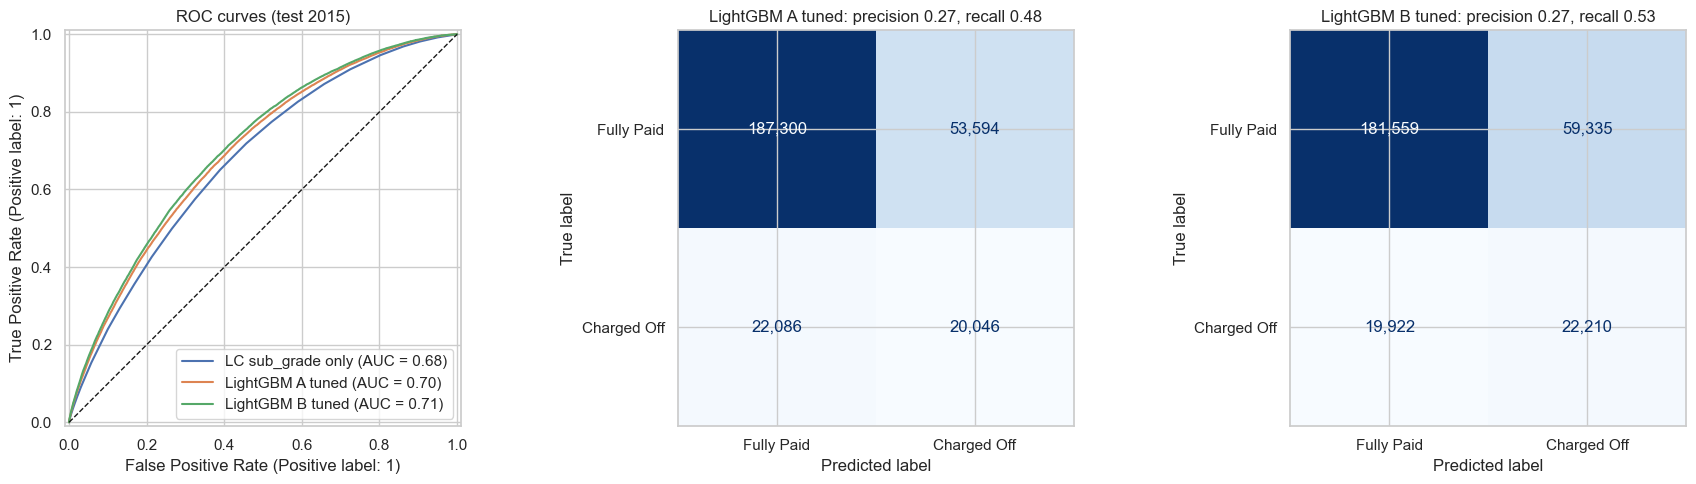

,threshold,precision,recall,share rejected,cost per loan,saving vs accept-all
LightGBM A tuned,0.18,0.272,0.476,0.260,0.079,0.182
LightGBM B tuned,0.17,0.272,0.527,0.288,0.077,0.202


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name in ["LC sub_grade only", FINAL_A, FINAL_B]:
    RocCurveDisplay.from_predictions(y_test, predictions[(name, "test")], name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves (test 2015)")

for ax, name in zip(axes[1:], [FINAL_A, FINAL_B]):
    flagged = predictions[(name, "test")] >= thresholds[name]
    ConfusionMatrixDisplay.from_predictions(y_test, flagged, display_labels=["Fully Paid", "Charged Off"],
                                            cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set(title=f"{name}: precision {precision_score(y_test, flagged):.2f}, "
                 f"recall {recall_score(y_test, flagged):.2f}")
plt.tight_layout()
plt.show()

pd.DataFrame({name: decision_summary(y_test, predictions[(name, "test")], thresholds[name])
              for name in thresholds}).T.round(3)

**Observation.** On the unseen 2015 loans, the ranking of the models is the same as on validation: Lending Club's sub-grade < Model A < Model B.
Test scores are slightly higher than validation scores because the final models were trained on more (and more recent) data (2007–2014).
No peer-reviewed result uses the same protocol (section 1.2), so our reference is Lending Club's own grade, which both models beat on unseen loans.

## 5. Conclusion

We developed and evaluated loan-outcome prediction models using Lending Club data. The pipeline removes leakage-prone features, engineers borrower-level ratios, filters for loan maturity, and uses chronological training, validation, and testing to reflect real-world prediction.

**Key findings**

- Tuned LightGBM achieved the best validation ROC-AUC (0.6932) and a test ROC-AUC of 0.709 with Lending Club's pricing features, compared with 0.699 without them.
- Model B outperformed Lending Club's sub-grade baseline on the test set, while Model A also demonstrated predictive value without the platform's pricing information.
- Class weighting and SMOTE did not improve ranking and worsened probability calibration. Hyperparameter tuning and model complexity produced only modest gains.
- The appendix demonstrates that including loans without sufficient maturity inflates validation performance, highlighting the importance of avoiding survivorship bias.

**Limitations and future work**

The dataset contains only accepted loans, validation and test sets contain only matured 36-month loans, and decision costs are assumed. Future work could estimate costs from repayment data, calibrate predicted probabilities, incorporate additional features, and evaluate temporal drift using survival analysis.

## 6. Appendix — The survivorship-bias trap

Our first exploratory notebook kept **every** loan marked Fully Paid or Charged Off, without checking whether the loan had had time to reach the end of its term.
It reached a validation ROC-AUC of **0.75**, well above the 0.69–0.71 of this notebook. Here we rebuild that setup to show where the difference comes from.

**The mechanism.** A loan only gets a final label (Fully Paid / Charged Off) when it ends, and the data was collected in December 2018.
A 60-month loan issued in 2015 should end in 2020. The only ones already "finished" in 2018 are those that **defaulted early** or were **repaid early**; borrowers repaying on schedule are still "Current" and are removed.
These finished-but-not-matured loans are therefore a biased sample, very rich in defaults, and the model learns a shortcut ("60-month loan ⇒ default") that only exists because of the date the data was extracted.
When a loan is approved we cannot know whether it will be one that ends early, so this shortcut is useless in practice — the score is inflated.

### 6.1 All finished loans, without the maturity filter

Same target, cleaning and features as in sections 2.3–2.6 (same columns dropped), but this time **every** finished loan is kept and flagged as matured or not.

In [ ]:
ENGINEERED = ["term_months", "credit_hist_years", "fico_avg", "loan_to_income",
              "revol_bal_to_income", "installment_to_income"]


def prepare_finished_loans(frame):
    # Same target, cleaning and feature engineering as sections 2.3-2.6, but WITHOUT the maturity filter.
    frame = frame.copy()
    frame["y"] = frame["loan_status"].map(TARGET_MAP).astype("int8")
    frame["issue_d"] = pd.to_datetime(frame["issue_d"], format="%b-%Y")
    frame["term_months"] = frame["term"].str.extract(r"(\d+)", expand=False).astype(int)
    issue_month = frame["issue_d"].dt.year * 12 + frame["issue_d"].dt.month
    frame["matured"] = issue_month + frame["term_months"] <= cutoff_month
    frame["emp_length"] = (frame["emp_length"].str.replace("< 1", "0", regex=False)
                                              .str.extract(r"(\d+)", expand=False).astype(float))
    earliest = pd.to_datetime(frame["earliest_cr_line"], format="%b-%Y")
    frame["credit_hist_years"] = (frame["issue_d"] - earliest).dt.days / 365.25
    frame["home_ownership"] = frame["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
    frame["annual_inc"] = frame["annual_inc"].replace(0, np.nan)
    frame["fico_avg"] = (frame["fico_range_low"] + frame["fico_range_high"]) / 2
    frame["loan_to_income"] = frame["loan_amnt"] / frame["annual_inc"]
    frame["revol_bal_to_income"] = frame["revol_bal"] / frame["annual_inc"]
    frame["installment_to_income"] = frame["installment"] * 12 / frame["annual_inc"]
    return frame[features_B + ["y", "issue_d", "matured"]]


raw_columns = [c for c in features_B if c not in ENGINEERED] + [
    "loan_status", "issue_d", "term", "earliest_cr_line", "fico_range_low", "fico_range_high"]
all_finished = prepare_finished_loans(pd.read_parquet(CACHE_PATH, columns=raw_columns))

cohorts = (all_finished
           .groupby([all_finished["issue_d"].dt.year.rename("issue_year"), "term_months"])
           .agg(n_loans=("y", "size"), default_rate=("y", "mean"), matured=("matured", "all")))
print(f"{len(all_finished):,} finished loans, of which {(~all_finished['matured']).sum():,} had not reached the end of their term")
cohorts.loc[2012:].round(3)

1,348,099 finished loans, of which 671,797 had not reached the end of their term


n_loans  default_rate  matured
issue_year term_months                                
2012       36             43470         0.136     True
           60              9897         0.277     True
2013       36            100422         0.123     True
           60             34382         0.251     True
2014       36            162570         0.137     True
           60             60533         0.311    False
2015       36            283026         0.149     True
           60             92520         0.364    False
2016       36            232361         0.198    False
           60             60744         0.364    False
2017       36            128551         0.200    False
           60             40770         0.330    False
2018       36             41272         0.132    False
           60             15046         0.226    False

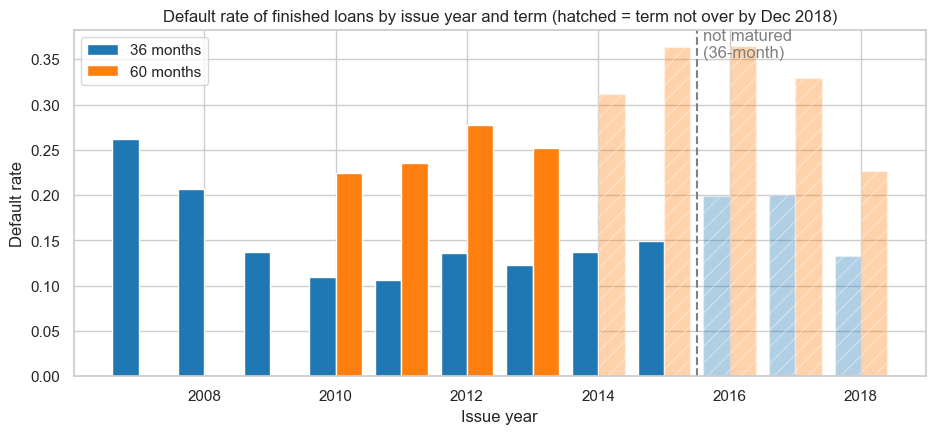

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for term, color, offset in [(36, "tab:blue", -0.2), (60, "tab:orange", 0.2)]:
    c = cohorts.xs(term, level="term_months")
    bars = ax.bar(c.index + offset, c["default_rate"], width=0.4, color=color, label=f"{term} months")
    for bar, is_matured in zip(bars, c["matured"]):
        if not is_matured:
            bar.set_alpha(0.35)
            bar.set_hatch("//")
ax.axvline(2015.5, color="grey", ls="--")
ax.text(2015.6, ax.get_ylim()[1] * 0.92, "not matured\n(36-month)", color="grey")
ax.set(title="Default rate of finished loans by issue year and term (hatched = term not over by Dec 2018)",
       xlabel="Issue year", ylabel="Default rate")
ax.legend()
plt.show()

**Observation.** The hatched bars (loans whose term was not over) are biased: 60-month loans from 2014–2015 reach 31–36 % defaults, and 36-month loans jump from 15 % (2015) to 20 % (2016–2017).
Since 2010, matured cohorts stay around 11–15 % (36-month) and 22–28 % (60-month). The extra defaults are not real: they are what is left after removing the loans still being repaid.
For 2018 the distortion goes the other way: those loans had barely started, so few had time to default.

### 6.2 Experiment 1 — Repeating our first notebook's setup

Train on January–September 2015, validate on October–December 2015, test on 2016–2018 (as in the first notebook), with all features of set B.
We run every model twice:

- **all terms** — as in the first notebook (includes the unmatured 60-month loans of 2015 and all of 2016–2018);
- **36-month only** — in 2015 these loans are all matured, so the training and validation sets become clean.

Note: the 2016–2018 test set is biased in **both** versions (even 36-month loans from those years had not matured), so only the validation columns can be compared fairly.

In [ ]:
def model_zoo(features):
    return {
        "Dummy": DummyClassifier(strategy="prior"),
        "LogReg": make_pipeline(make_linear_preprocessor(features),
                                LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Random forest": make_rf(features),
        "HGB (tuned settings)": make_tuned_hgb(features),
        "XGBoost (tuned settings)": make_tuned_xgb(features),
        "LightGBM (tuned settings)": make_tuned_lgbm(features),
    }


def run_experiment(train_set, eval_sets, features=features_B):
    # Fit every model on train_set; return the ROC-AUC on each evaluation set and the fitted models.
    rows, fitted = [], {}
    for model_name, model in model_zoo(features).items():
        model.fit(train_set[features], train_set["y"])
        fitted[model_name] = model
        for set_name, data in eval_sets.items():
            proba = model.predict_proba(data[features])[:, 1]
            rows.append({"model": model_name, "evaluated on": set_name,
                         "roc_auc": roc_auc_score(data["y"], proba)})
    for set_name, data in eval_sets.items():   # no-training reference points
        rows.append({"model": "LC sub_grade only", "evaluated on": set_name,
                     "roc_auc": roc_auc_score(data["y"], data["sub_grade"].map(subgrade_rank))})
        rows.append({"model": "term alone", "evaluated on": set_name,
                     "roc_auc": roc_auc_score(data["y"], data["term_months"]) if data["term_months"].nunique() > 1 else np.nan})
    return pd.DataFrame(rows), fitted


issue = all_finished["issue_d"]
exp1_sets = {
    "train": all_finished[(issue >= "2015-01-01") & (issue < "2015-10-01")],
    "valid Oct-Dec 2015": all_finished[(issue >= "2015-10-01") & (issue < "2016-01-01")],
    "test 2016-2018": all_finished[issue >= "2016-01-01"],
}
only_36 = {name: data[data["term_months"] == 36] for name, data in exp1_sets.items()}

pd.DataFrame({
    (version, name): {"n_loans": len(data), "default_rate": data["y"].mean(),
                      "share not matured": 1 - data["matured"].mean()}
    for version, sets in [("all terms", exp1_sets), ("36-month only", only_36)]
    for name, data in sets.items()
}).T.round(3)

n_loans  default_rate  share not matured
all terms     train               260649.0         0.203              0.254
              valid Oct-Dec 2015  114897.0         0.199              0.228
              test 2016-2018      518744.0         0.224              1.000
36-month only train               194357.0         0.149              0.000
              valid Oct-Dec 2015   88669.0         0.148              0.000
              test 2016-2018      402184.0         0.192              1.000

In [ ]:
exp1_all, fitted_all = run_experiment(exp1_sets["train"], {k: v for k, v in exp1_sets.items() if k != "train"})
exp1_36, fitted_36 = run_experiment(only_36["train"], {k: v for k, v in only_36.items() if k != "train"})

exp1 = pd.concat([exp1_all.assign(version="all terms"), exp1_36.assign(version="36-month only")])
exp1_table = exp1.pivot_table(index="model", columns=["evaluated on", "version"], values="roc_auc", sort=False)
exp1_table.round(3)

evaluated on,valid Oct-Dec 2015,test 2016-2018,valid Oct-Dec 2015,test 2016-2018
version,all terms,all terms,36-month only,36-month only
model,,,,
Dummy,0.500,0.500,0.500,0.500
LogReg,0.747,0.714,0.711,0.706
Random forest,0.743,0.710,0.706,0.702
HGB (tuned settings),0.749,0.717,0.712,0.706
XGBoost (tuned settings),0.752,0.719,0.717,0.711
LightGBM (tuned settings),0.752,0.720,0.716,0.710
LC sub_grade only,0.714,0.687,0.682,0.677
term alone,0.623,0.571,NaN,NaN


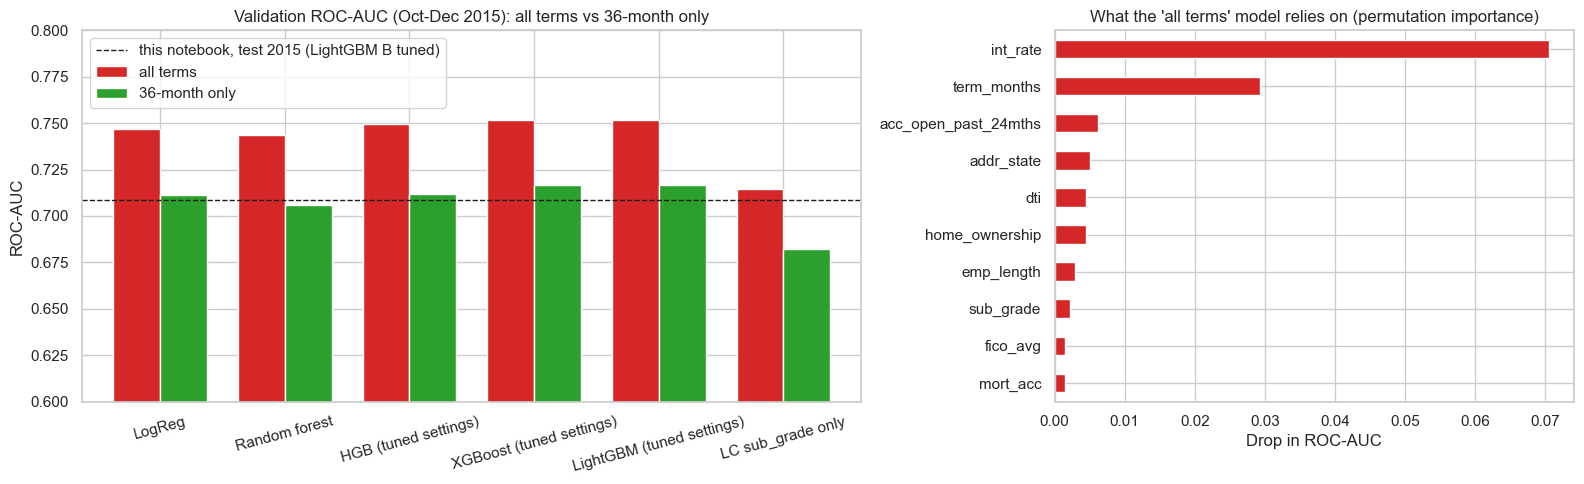

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 2]})

valid = exp1_table["valid Oct-Dec 2015"].drop(index=["Dummy", "term alone"])
valid.plot.bar(ax=axes[0], rot=15, color=["tab:red", "tab:green"], width=0.75)
our_test_auc = roc_auc_score(y_test, predictions[(FINAL_B, "test")])
axes[0].axhline(our_test_auc, color="k", ls="--", lw=1, label=f"this notebook, test 2015 ({FINAL_B})")
axes[0].set(title="Validation ROC-AUC (Oct-Dec 2015): all terms vs 36-month only", ylim=(0.6, 0.8),
            xlabel="", ylabel="ROC-AUC")
axes[0].legend(loc="upper left")

sample = exp1_sets["valid Oct-Dec 2015"].sample(20_000, random_state=RANDOM_STATE)
importance = permutation_importance(fitted_all["HGB (tuned settings)"], sample[features_B], sample["y"],
                                    scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE)
(pd.Series(importance.importances_mean, index=features_B).sort_values().tail(10)
   .plot.barh(ax=axes[1], color="tab:red"))
axes[1].set(title="What the 'all terms' model relies on (permutation importance)", xlabel="Drop in ROC-AUC")
plt.tight_layout()
plt.show()

**Observation.** On the complete data we reproduce the first notebook's result: with all loan terms, the validation ROC-AUC is 0.743–0.752 (0.752 for XGBoost and LightGBM).
Keeping only 36-month loans — the only change — lowers **every** model by 0.035–0.037, to 0.706–0.717: the level of this notebook (0.709 on 2015).
Even Lending Club's sub-grade, which involves no training at all, goes from 0.682 to 0.714: the unmatured loans also make the *evaluation* easier.

The permutation importance shows the shortcut: in the "all terms" model `int_rate` and `term_months` are by far the two most important features (`term_months` alone already gives 0.623). 60-month loans are priced with higher interest rates, so `int_rate` most likely carries part of the same shortcut.
The 2016–2018 test scores are not trustworthy in either version: all of those loans are unmatured (default rate 22.4 % with all terms, 19.2 % for 36-month loans, against 14.9 % for matured 2015 loans).

### 6.3 Experiment 2 — our own split, with and without the maturity filter

The training years (2007–2013) contain only matured loans either way (a 60-month loan issued in December 2013 ends in December 2018), so the models trained in section 3 can be reused unchanged.
We only change **which loans are evaluated**: the matured loans used in this notebook, or all finished loans of the same year (adding the unmatured 60-month loans).
Note: here all models were trained on 2007–2013 only (no refit on 2014), so the 2015 numbers differ slightly from section 4.7.

In [ ]:
assert all_finished.loc[all_finished["issue_d"].dt.year <= 2013, "matured"].all()

year = all_finished["issue_d"].dt.year
exp2_sets = {
    ("2014", "matured only (this notebook)"): val,
    ("2014", "all finished loans"): all_finished[year == 2014],
    ("2015", "matured only (this notebook)"): test,
    ("2015", "all finished loans"): all_finished[year == 2015],
}
exp2_models = ["LogReg B", "RF B", "HGB B tuned", "XGBoost B tuned", "LightGBM B tuned"]

rows = []
for (eval_year, version), data in exp2_sets.items():
    for name in exp2_models:
        model, feats = models[name]
        rows.append({"model": name, "year": eval_year, "version": version,
                     "roc_auc": roc_auc_score(data["y"], model.predict_proba(data[feats])[:, 1])})
    rows.append({"model": "LC sub_grade only", "year": eval_year, "version": version,
                 "roc_auc": roc_auc_score(data["y"], data["sub_grade"].map(subgrade_rank))})
exp2 = pd.DataFrame(rows)
exp2_table = exp2.pivot_table(index="model", columns=["year", "version"], values="roc_auc", sort=False)
exp2_table.round(3)

year                                      2014                     \
version           matured only (this notebook) all finished loans   
model                                                               
LogReg B                                 0.684              0.714   
RF B                                     0.685              0.714   
HGB B tuned                              0.688              0.717   
XGBoost B tuned                          0.692              0.720   
LightGBM B tuned                         0.693              0.721   
LC sub_grade only                        0.660              0.688   

year                                      2015                     
version           matured only (this notebook) all finished loans  
model                                                              
LogReg B                                 0.693              0.729  
RF B                                     0.694              0.730  
HGB B tuned                              0.696              0.732  
XGBoost B tuned                          0.700              0.735  
LightGBM B tuned                         0.701              0.735  
LC sub_grade only                        0.679              0.710

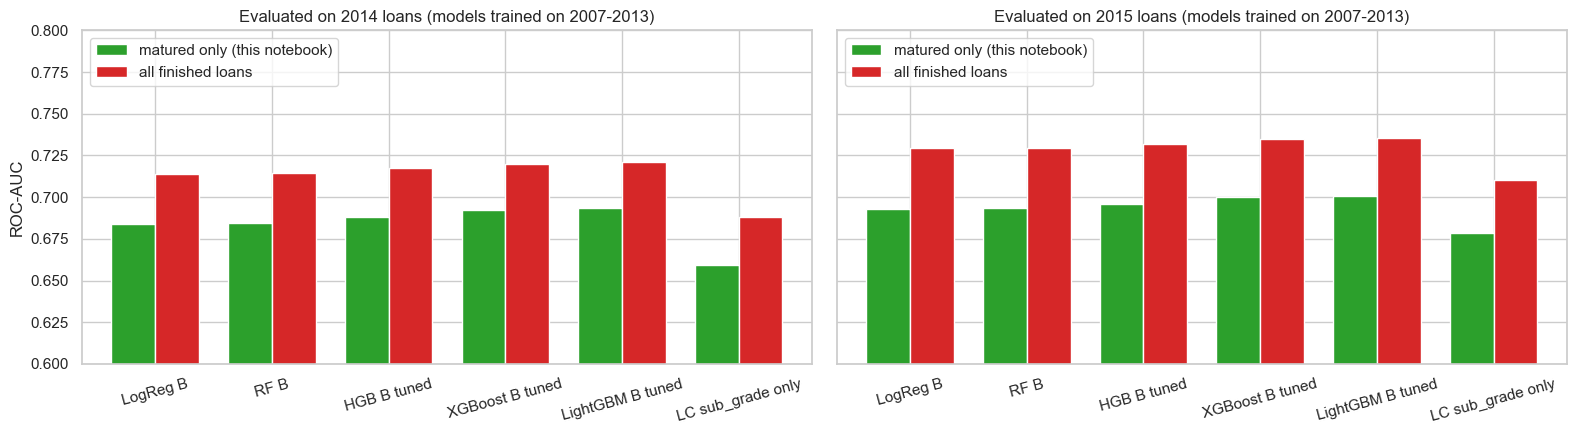

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, eval_year in zip(axes, ["2014", "2015"]):
    exp2_table[eval_year].plot.bar(ax=ax, rot=15, color=["tab:green", "tab:red"], width=0.75)
    ax.set(title=f"Evaluated on {eval_year} loans (models trained on 2007-2013)", ylim=(0.6, 0.8),
           xlabel="", ylabel="ROC-AUC")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Observation.** Here the models are exactly the same; only the loans they are scored on change.
Adding the unmatured 60-month loans raises every score by 0.03–0.04 (LightGBM: 0.693 → 0.721 on 2014, 0.701 → 0.735 on 2015), and Lending Club's sub-grade rises just as much (0.660 → 0.688, 0.679 → 0.710).
So the higher score does not come from a better model: the added loans are risky and rich in defaults (31–36 %), which makes them easy to rank and the test easier. A ROC-AUC only means something together with the population it was measured on.

### 6.4 Conclusion of the appendix

- The first notebook's 0.75 is reproduced exactly, so its code was not wrong and no leaking column was used: the difference comes entirely from **which loans are included**.
- Removing the loans whose term had not ended brings every model back to 0.70–0.72, the level of this notebook.
- The bias acts twice: in **training** (the model learns a "60-month / high interest rate ⇒ default" shortcut) and in **evaluation** (an easier test set — even the no-training sub-grade baseline gains about 0.03).
- Lesson: on loan data, define the target only on loans whose outcome could be fully observed, and compare scores only on the same population. This is why section 2.4 keeps matured loans only, even though it leaves no 60-month loans after 2013.